# Comparing tTEM with tTEM

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from anemone.experiment import *
from anemone.inversion  import *
from anemone.forwards import *

In [2]:
gpu = torch.device('cpu')
cmdl = Resistivity.few_layers(torch.ones(3)*50., torch.ones(2)*20.)

In [3]:
tx = Loop.square(3)
rx = Receiver(x=13)

In [4]:
tgates = torch.logspace(-5, -3, 21)

recfilters = FilterChain([
    ButterworthFilter(6.79e5),
])
fwr = Forward(tx, rx, tgates, Waveform.example(), recfilters, tolerance=1e-5)

In [5]:
res = torch.tensor([10, 200, 20])
thick1 = torch.linspace(0.1, 5, 25)

In [6]:
thick = torch.tensor([5, 10])
data = fwr(res, thick)

In [7]:
thick_stack = np.vstack([thick1, np.ones_like(thick1)*10])
rho = res[:, None]
thick = torch.from_numpy(thick_stack)

In [8]:
class InvSensitivity(Tikhonov):
    def C_est(self, mvec):
        from torch.linalg import inv
        G = self.jacobian(mvec)
        C = inv(G.T @ torch.diag(self.recip_error_squared) @ G)
        return C
    
    def sensitivity_factor(self, mvec):
        C = self.C_est(mvec)
        diag = torch.sqrt(torch.diag(C))
        return torch.exp(diag)

    def plot_sensitivity_analysis(self, ax=None, x_offset=0, cbar=False):
        stdf, model = self.sensitivity_factor(self.model.vec), self.model
        import matplotlib.colors as colors
        cmap = colors.ListedColormap(['red', 'darkorange', 'yellow', 'aqua', 'blue'])
        norm = colors.BoundaryNorm(np.array([1., 1.2, 1.5, 2., 3., 4.]), cmap.N)    
        if ax is None:
            fig,ax = plt.subplots()

        dy = np.arange(len(model.vec)+1)
        tick_pos = (dy[:-1]+dy[1:])/2
        tick_lab = [f'$\\rho_{i+1}$' for i in range(len(model.values[0]))]
        tick_lab +=[f'thk$_{i+1}$' for i in range(len(model.values[1]))]
        dx = np.outer(np.ones_like(dy), np.array([-0.5, 0.5]))+x_offset
        dy = np.outer(dy, np.ones(2))
        val = stdf[:, None].cpu().numpy()
        val[np.isnan(val)] = 5.
        val[val>4] = 5
        pcm = ax.pcolormesh(dx, dy, val, cmap=cmap, norm=norm, edgecolor='k', linewidth=0.5)
        ax.set_yticks(tick_pos)
        ax.set_yticklabels(tick_lab)
        if cbar:
            import matplotlib.pyplot as plt
            plt.colorbar(pcm, ax=ax, label='sensitivity factor')
        return ax
    
# fastJac = fastjacobian(Tikhonov)


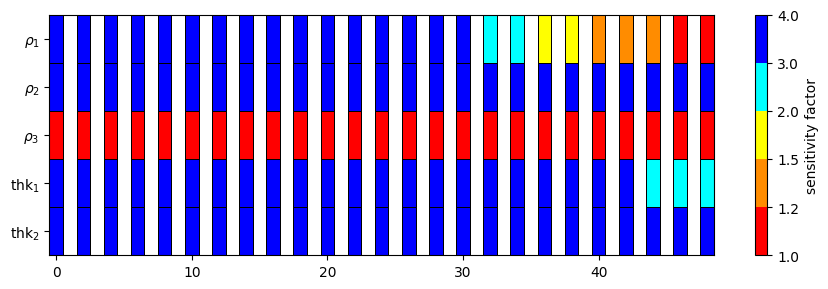

In [15]:
cm = plt.get_cmap('Spectral')

fig,axs = plt.subplots(1,1, sharex=True, figsize=(9,3))

for i,thk in enumerate(thick1):
    thick = torch.tensor([thk, 10])
    dbdt = fwr(rho, thick)
    dbdt_err = compute_relstd(fwr.times, dbdt, current=30.)

    m_true = LogResistivity.few_layers(res, thick)
    inv = InvSensitivity(dbdt, dbdt*dbdt_err, m_true, fwr)
    inv.setup_matrices()
    inv.plot_sensitivity_analysis(ax=axs, x_offset=i*2, cbar=i==2)

    # cmd_smooth = LogResistivity.smooth(torch.ones(31, dtype=torch.double)*50, torch.cumsum(torch.logspace(0,1.5,30), 0))
    # dbdt_with_noise = torch.abs(dbdt + torch.randn(len(dbdt))*dbdt*dbdt_err)


    # inv2 = Inversion(dbdt_with_noise, dbdt*dbdt_err, cmd_smooth, fwr, logger=print, data_transform=torch.log10)
    
axs.set_ylim(5,0)

plt.tight_layout()